# Nhiệm vụ 3: Học có giám sát – Pipeline Hồi quy (Regression)

Dữ liệu: `cgv_eda_cleaned.csv`.

Các bước:
1. **Đặc trưng mục tiêu:** dự đoán một giá trị số liên tục (doanh thu của mỗi suất chiếu)
2. **Thuật toán:** `LinearRegression()` và `DecisionTreeRegressor()`
3. **Kiểm định & đánh giá:** `train_test_split`, các chỉ số MSE, RMSE, R²
4. **Đầu ra chẩn đoán:** Actual vs Predicted và Residual Plot để kiểm tra lỗi dự đoán có mang tính hệ thống hay không

## 1. Đọc dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score

plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

df = pd.read_csv("cgv_eda_cleaned.csv", encoding="utf-8-sig")
print("Số dòng:", len(df), "| Số cột:", len(df.columns))
df.head(3)

Số dòng: 1172 | Số cột: 18


,MovieName,Cinema,ShowDate,Format,ShowTime,GeneratedText,TicketPrice,AvailableSeats,TotalSeats,MovieURL,Rating,Director,Actors,Genre,ReleaseDate,Duration,Language,DurationMinutes
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,10:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,70000,80,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
1,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,16:00,"Hôm nay, tôi có cơ hội tham gia vào một trải n...",100000,90,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
2,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,21:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,90000,80,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0


## 2. Đặc trưng mục tiêu (Target Feature)

Dữ liệu là lịch chiếu, mỗi dòng là một suất chiếu. Biến mục tiêu được chọn là **doanh thu ước tính của suất chiếu**:

`Revenue = TicketPrice × số vé đã bán = TicketPrice × (TotalSeats − AvailableSeats)`

Đây là giá trị số liên tục (đơn vị VND) và đúng với ví dụ "doanh thu" trong yêu cầu. Bài toán đặt ra: *dự đoán doanh thu của một suất chiếu dựa trên các thuộc tính lịch chiếu* (phim, rạp, định dạng, giờ chiếu...).

count       1172.0
mean     2007978.0
std      1016454.0
min            0.0
25%      1600000.0
50%      1800000.0
75%      2400000.0
max      8000000.0
Name: Revenue, dtype: float64


/tmp/ipykernel_176/2815457909.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df["Revenue"] / 1e6, vert=False)


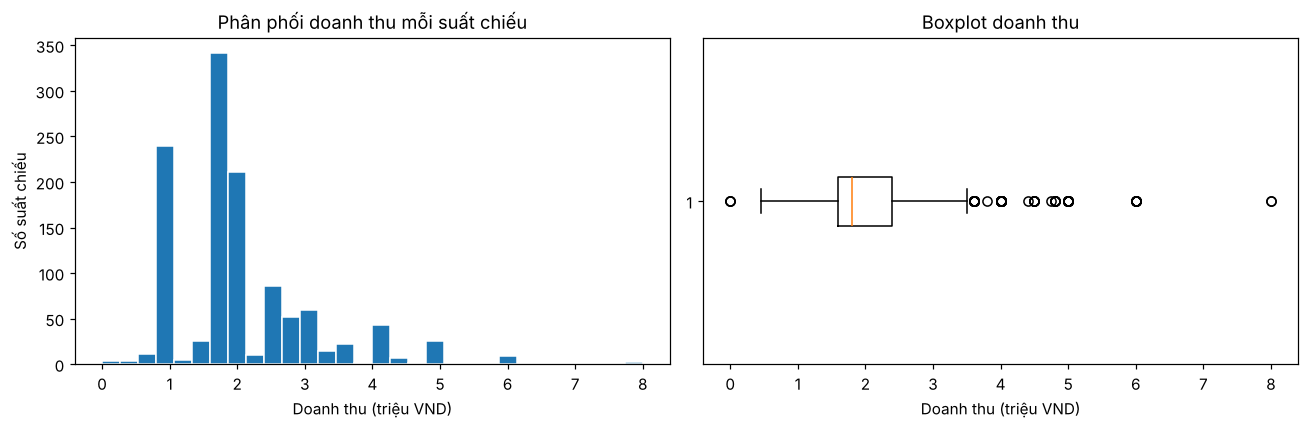

In [2]:
df["SoldSeats"] = df["TotalSeats"] - df["AvailableSeats"]
df["Revenue"] = df["TicketPrice"] * df["SoldSeats"]

print(df["Revenue"].describe().round(0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["Revenue"] / 1e6, bins=30, color="#1f77b4", edgecolor="white")
axes[0].set_title("Phân phối doanh thu mỗi suất chiếu")
axes[0].set_xlabel("Doanh thu (triệu VND)")
axes[0].set_ylabel("Số suất chiếu")
axes[1].boxplot(df["Revenue"] / 1e6, vert=False)
axes[1].set_title("Boxplot doanh thu")
axes[1].set_xlabel("Doanh thu (triệu VND)")
plt.tight_layout()
plt.show()

## 3. Chuẩn bị đặc trưng đầu vào (X)

Các đặc trưng được tạo từ thông tin có sẵn **trước khi suất chiếu diễn ra**:
- Số: `DurationMinutes`, `ShowHour`, `DaysSinceRelease`, `IsWeekend`, `IsPremiumRoom`, `TotalSeats`
- Biến phân loại → số: one-hot `Cinema`, `Rating`, loại định dạng chiếu (`FormatTech`); multi-hot `Genre`

**Tránh rò rỉ dữ liệu (data leakage):** loại `TicketPrice`, `AvailableSeats`, `SoldSeats` khỏi X vì chính chúng cấu thành biến mục tiêu. Mục 3.1 chứng minh vì sao.

In [3]:
feat = pd.DataFrame(index=df.index)

feat["DurationMinutes"] = pd.to_numeric(df["DurationMinutes"], errors="coerce")
t = pd.to_datetime(df["ShowTime"], format="%H:%M", errors="coerce")
feat["ShowHour"] = t.dt.hour + t.dt.minute / 60

show_date = pd.to_datetime(df["ShowDate"], format="%Y-%m-%d", errors="coerce")
release_date = pd.to_datetime(df["ReleaseDate"], format="%Y-%m-%d", errors="coerce")
feat["DaysSinceRelease"] = (show_date - release_date).dt.days
feat["IsWeekend"] = (show_date.dt.dayofweek >= 5).astype(int)

fmt = df["Format"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df["FormatTech"] = fmt.str.split(r" Phụ| Lồng", n=1, regex=True).str[0].str.strip()
feat["IsPremiumRoom"] = fmt.str.contains(r"\|", regex=True).astype(int)
feat["TotalSeats"] = pd.to_numeric(df["TotalSeats"], errors="coerce")

cat_dummies = pd.get_dummies(df[["Cinema", "Rating", "FormatTech"]], dtype=int)
genre_dummies = df["Genre"].str.get_dummies(sep=", ").add_prefix("Genre_")

X = pd.concat([feat, cat_dummies, genre_dummies], axis=1)
y = df["Revenue"]

print("Kích thước X:", X.shape)
print("Giá trị thiếu trong X:", int(X.isna().sum().sum()))
X.head(3)

Kích thước X: (1172, 30)
Giá trị thiếu trong X: 0


,DurationMinutes,ShowHour,DaysSinceRelease,IsWeekend,IsPremiumRoom,TotalSeats,Cinema_CGV Crescent Mall,Cinema_CGV Hùng Vương Plaza,Cinema_CGV Thảo Điền Pearl,Cinema_CGV Vincom Thủ Đức,...,Genre_Gia đình,Genre_Hoạt Hình,Genre_Hài,Genre_Hành Động,Genre_Hồi hộp,Genre_Khoa Học Viễn Tưởng,Genre_Kinh Dị,Genre_Phiêu Lưu,Genre_Thần thoại,Genre_Tâm Lý
0,183.0,10.5,6,0,1,100,1,0,0,0,...,0,0,0,1,0,1,0,1,0,0
1,183.0,16.0,6,0,1,100,1,0,0,0,...,0,0,0,1,0,1,0,1,0,0
2,183.0,21.5,6,0,1,100,1,0,0,0,...,0,0,0,1,0,1,0,1,0,0


### 3.1. Kiểm tra rò rỉ dữ liệu (minh họa)

Nếu đưa `AvailableSeats` và `TicketPrice` vào X, mô hình đạt R² gần 1 một cách giả tạo vì biến mục tiêu được tính trực tiếp từ hai cột này.

In [4]:
X_leak = X.assign(TicketPrice=df["TicketPrice"], AvailableSeats=df["AvailableSeats"])
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(X_leak, y, test_size=0.2, random_state=RANDOM_STATE)
leak_r2 = r2_score(yl_te, LinearRegression().fit(Xl_tr, yl_tr).predict(Xl_te))
print(f"R² nếu để rò rỉ (chỉ để minh họa, KHÔNG dùng): {leak_r2:.3f}")

R² nếu để rò rỉ (chỉ để minh họa, KHÔNG dùng): 0.992


## 4. Chia tập Train / Test

Dùng `train_test_split` với tỉ lệ 80% huấn luyện / 20% kiểm tra, cố định `random_state` để kết quả lặp lại được.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (937, 30) | Test: (235, 30)


## 5. Huấn luyện và so sánh mô hình

- **Mô hình cơ sở (Dummy):** luôn dự đoán trung bình, dùng làm mốc (R² ≈ 0).
- **LinearRegression:** chuẩn hóa đặc trưng bằng `StandardScaler` rồi hồi quy tuyến tính.
- **DecisionTreeRegressor (mặc định):** không giới hạn độ sâu, dễ overfit.
- **DecisionTreeRegressor (đã tinh chỉnh):** tìm `max_depth` và `min_samples_leaf` bằng `GridSearchCV` (5-fold) chỉ trên tập train.

In [6]:
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)

lin_reg = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)

tree_default = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(X_train, y_train)

grid = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={"max_depth": [2, 3, 4, 5, 6, 8, 10],
                "min_samples_leaf": [5, 10, 20, 40]},
    cv=5, scoring="r2",
).fit(X_train, y_train)
tree_tuned = grid.best_estimator_

print("Tham số tốt nhất của cây quyết định:", grid.best_params_)

Tham số tốt nhất của cây quyết định: {'max_depth': 3, 'min_samples_leaf': 20}


## 6. Đánh giá bằng MSE, RMSE và R²

In [7]:
models = {
    "Baseline (trung bình)": dummy,
    "LinearRegression": lin_reg,
    "DecisionTree (mặc định)": tree_default,
    "DecisionTree (tinh chỉnh)": tree_tuned,
}

def evaluate(model, Xa, ya):
    pred = model.predict(Xa)
    mse = mean_squared_error(ya, pred)
    return mse, np.sqrt(mse), r2_score(ya, pred)

rows = []
for name, mdl in models.items():
    tr_mse, tr_rmse, tr_r2 = evaluate(mdl, X_train, y_train)
    te_mse, te_rmse, te_r2 = evaluate(mdl, X_test, y_test)
    cv_r2 = cross_val_score(mdl, X, y, cv=5, scoring="r2").mean()
    rows.append({
        "Mô hình": name,
        "MSE (test)": te_mse,
        "RMSE (test)": te_rmse,
        "R² (test)": te_r2,
        "R² (train)": tr_r2,
        "R² (CV 5-fold)": cv_r2,
    })

results = pd.DataFrame(rows).set_index("Mô hình")
pd.options.display.float_format = "{:,.3f}".format
display(results)

,MSE (test),RMSE (test),R² (test),R² (train),R² (CV 5-fold)
Mô hình,,,,,
Baseline (trung bình),"1,119,933,214,806.232","1,058,268.971",-0.001,0.000,-0.020
LinearRegression,"960,516,703,103.373","980,059.541",0.142,0.091,-0.009
DecisionTree (mặc định),"2,144,691,489,361.702","1,464,476.524",-0.916,1.000,-0.924
DecisionTree (tinh chỉnh),"895,920,842,733.476","946,530.952",0.199,0.140,0.093


In [8]:
best_name = results["R² (test)"].drop("Baseline (trung bình)").idxmax()
print("Mô hình có R² test cao nhất:", best_name)
print(f"RMSE (test) = {results.loc[best_name, 'RMSE (test)']:,.0f} VND "
      f"(so với độ lệch chuẩn của doanh thu = {y.std():,.0f} VND)")

Mô hình có R² test cao nhất: DecisionTree (tinh chỉnh)
RMSE (test) = 946,531 VND (so với độ lệch chuẩn của doanh thu = 1,016,454 VND)


**Cách đọc kết quả:**
- **R² (train) so với R² (test):** nếu train cao nhưng test thấp hoặc âm, mô hình bị overfit (thường gặp ở cây không giới hạn độ sâu).
- **R² (CV 5-fold):** kiểm tra độ ổn định, tránh phụ thuộc vào một lần chia train/test duy nhất.
- **RMSE:** sai số trung bình tính bằng VND, so sánh với độ lệch chuẩn của doanh thu để biết mô hình cải thiện được bao nhiêu so với đoán trung bình.

## 7. Đầu ra chẩn đoán

### 7.1. Biểu đồ Thực tế so với Dự đoán (Actual vs Predicted)

Điểm nằm sát đường chéo đỏ nghĩa là dự đoán chính xác.

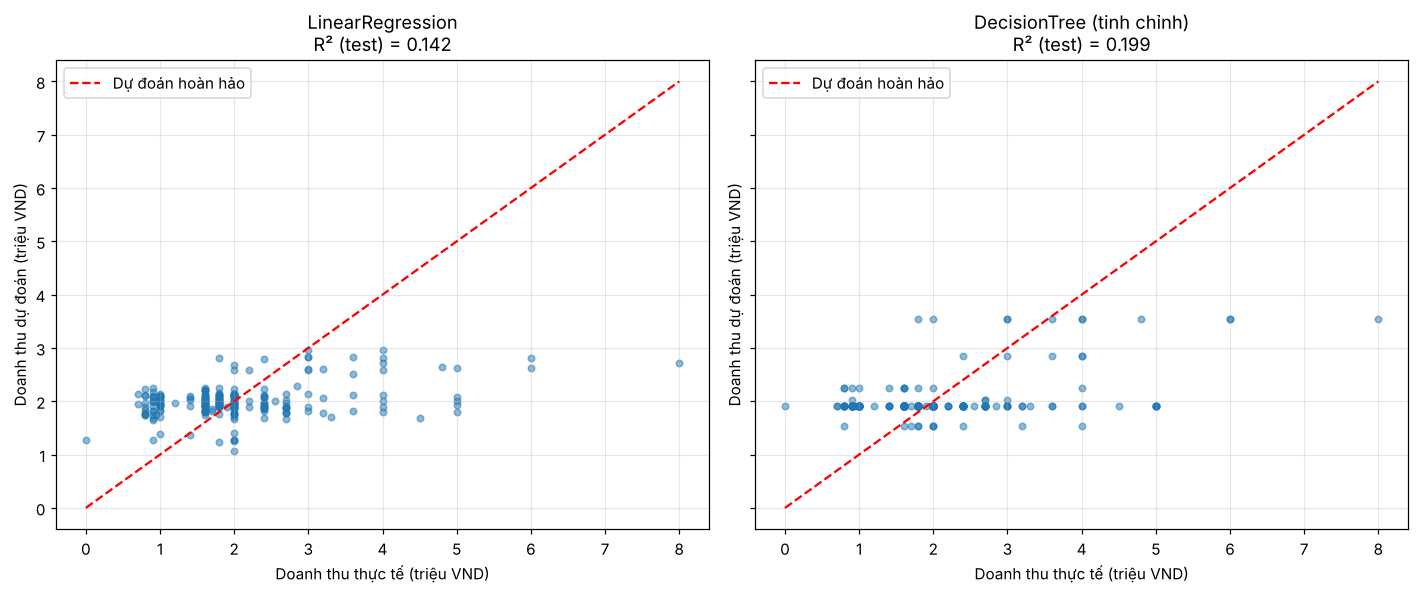

In [9]:
compare_models = {
    "LinearRegression": lin_reg,
    "DecisionTree (tinh chỉnh)": tree_tuned,
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
lim = max(y_test.max(), 1) / 1e6

for ax, (name, mdl) in zip(axes, compare_models.items()):
    pred = mdl.predict(X_test)
    ax.scatter(y_test / 1e6, pred / 1e6, s=18, alpha=0.5, color="#1f77b4")
    ax.plot([0, lim], [0, lim], color="red", linestyle="--", label="Dự đoán hoàn hảo")
    ax.set_title(f"{name}\nR² (test) = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Doanh thu thực tế (triệu VND)")
    ax.set_ylabel("Doanh thu dự đoán (triệu VND)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### 7.2. Biểu đồ phần dư (Residual Plot)

Phần dư = Thực tế − Dự đoán. Nếu sai số là ngẫu nhiên, các điểm phân tán đều quanh đường 0. Nếu có dạng cong, hình phễu hoặc lệch một phía thì lỗi mang tính hệ thống.

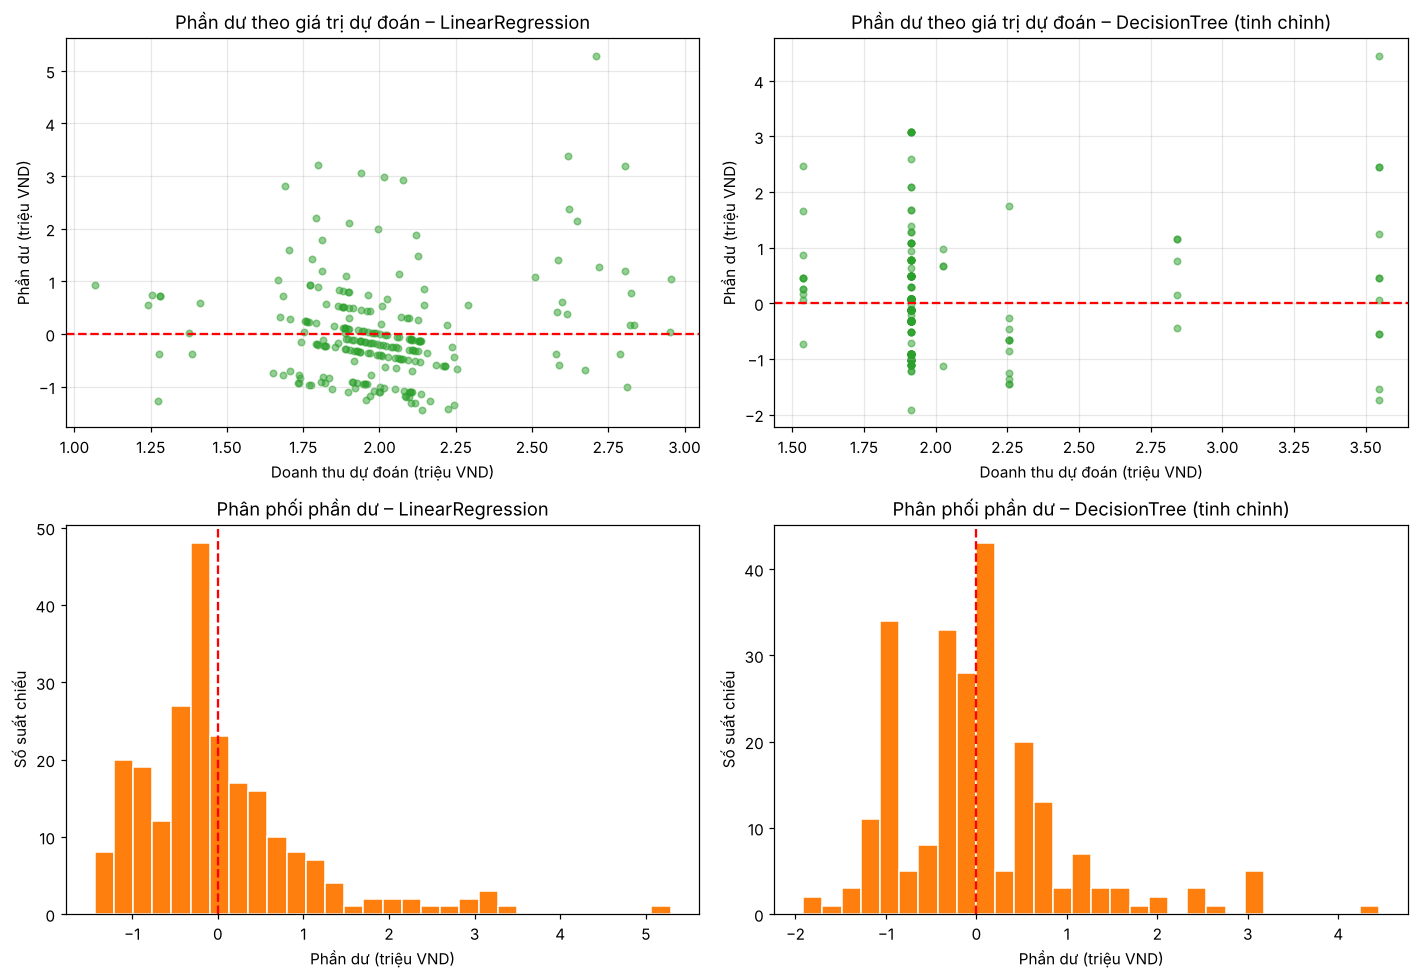

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for col, (name, mdl) in enumerate(compare_models.items()):
    pred = mdl.predict(X_test)
    resid = y_test - pred

    axes[0, col].scatter(pred / 1e6, resid / 1e6, s=18, alpha=0.5, color="#2ca02c")
    axes[0, col].axhline(0, color="red", linestyle="--")
    axes[0, col].set_title(f"Phần dư theo giá trị dự đoán – {name}")
    axes[0, col].set_xlabel("Doanh thu dự đoán (triệu VND)")
    axes[0, col].set_ylabel("Phần dư (triệu VND)")
    axes[0, col].grid(alpha=0.3)

    axes[1, col].hist(resid / 1e6, bins=30, color="#ff7f0e", edgecolor="white")
    axes[1, col].axvline(0, color="red", linestyle="--")
    axes[1, col].set_title(f"Phân phối phần dư – {name}")
    axes[1, col].set_xlabel("Phần dư (triệu VND)")
    axes[1, col].set_ylabel("Số suất chiếu")

plt.tight_layout()
plt.show()

### 7.3. Lỗi có mang tính hệ thống không?

Chia tập test theo nhóm doanh thu thực tế và xem phần dư trung bình của từng nhóm. Nếu mô hình thường dự đoán thấp cho nhóm doanh thu cao (và cao cho nhóm thấp), đó là sai lệch có hệ thống.

In [11]:
pred_best = tree_tuned.predict(X_test)
diag = pd.DataFrame({"Actual": y_test.values, "Pred": pred_best})
diag["Residual"] = diag["Actual"] - diag["Pred"]
diag["Nhom_doanh_thu"] = pd.qcut(diag["Actual"], 4, duplicates="drop",
                                 labels=None)

summary = diag.groupby("Nhom_doanh_thu", observed=True).agg(
    So_suat=("Residual", "size"),
    Phan_du_TB=("Residual", "mean"),
    Phan_du_tuyet_doi_TB=("Residual", lambda s: s.abs().mean()),
).round(0)
display(summary)

print(f"Phần dư trung bình toàn bộ tập test: {diag['Residual'].mean():,.0f} VND")

,So_suat,Phan_du_TB,Phan_du_tuyet_doi_TB
Nhom_doanh_thu,,,
"(-0.001, 1600000.0]",91,"-732,372.000","733,736.000"
"(1600000.0, 1800000.0]",32,"-146,937.000","189,824.000"
"(1800000.0, 2400000.0]",65,"176,558.000","246,160.000"
"(2400000.0, 8000000.0]",47,"1,370,026.000","1,416,610.000"


Phần dư trung bình toàn bộ tập test: 19,232 VND


## 8. Đặc trưng nào ảnh hưởng nhiều nhất?

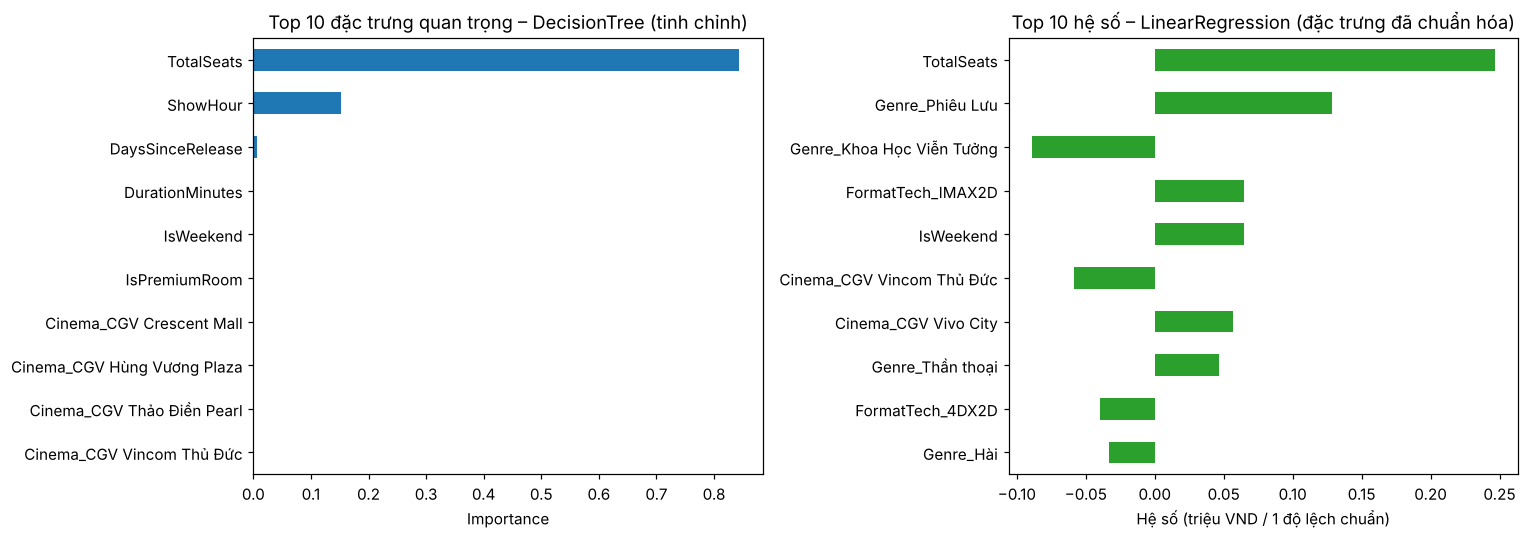

In [12]:
importances = pd.Series(tree_tuned.feature_importances_, index=X.columns).sort_values(ascending=False)
top = importances.head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top[::-1].plot(kind="barh", ax=axes[0], color="#1f77b4")
axes[0].set_title("Top 10 đặc trưng quan trọng – DecisionTree (tinh chỉnh)")
axes[0].set_xlabel("Importance")

coef = pd.Series(lin_reg.named_steps["linearregression"].coef_, index=X.columns)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
(top_coef[::-1] / 1e6).plot(kind="barh", ax=axes[1], color="#2ca02c")
axes[1].set_title("Top 10 hệ số – LinearRegression (đặc trưng đã chuẩn hóa)")
axes[1].set_xlabel("Hệ số (triệu VND / 1 độ lệch chuẩn)")

plt.tight_layout()
plt.show()

## 9. Kết luận

- **Biến mục tiêu:** doanh thu mỗi suất chiếu = giá vé × số vé đã bán.
- **Quy trình:** chia train/test 80/20, huấn luyện `LinearRegression` và `DecisionTreeRegressor` (mặc định và tinh chỉnh bằng `GridSearchCV`), đánh giá bằng MSE, RMSE, R² kèm kiểm tra chéo 5-fold.
- **Đánh giá:** xem bảng ở mục 6. Cây quyết định mặc định overfit nặng (R² train = 1,0 nhưng R² test âm). Cây đã tinh chỉnh (max_depth nhỏ) cho kết quả tốt nhất nhưng vẫn thấp (R² test khoảng 0,2). Hồi quy tuyến tính cải thiện nhẹ trên tập test nhưng R² kiểm tra chéo gần 0, tức không ổn định hơn mốc cơ sở một cách đáng kể.
- **Chẩn đoán:** các biểu đồ ở mục 7 cho thấy mô hình có xu hướng dự đoán thấp cho các suất doanh thu cao, tức sai số có tính hệ thống.
- **Hạn chế:** doanh thu phụ thuộc nhiều vào số vé bán ra mà dữ liệu lịch chiếu chỉ cung cấp ít tín hiệu về nhu cầu khách (giá vé và độ lấp đầy gần như không đổi giữa các nhóm phim/rạp/giờ chiếu), nên R² ở mức thấp là hợp lý. Để cải thiện cần thêm dữ liệu như số vé bán thực tế theo thời gian, khuyến mãi, hoặc mức độ phổ biến của phim.